## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [38]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Evie McMahan

**Date:** 10/20/26

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [39]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

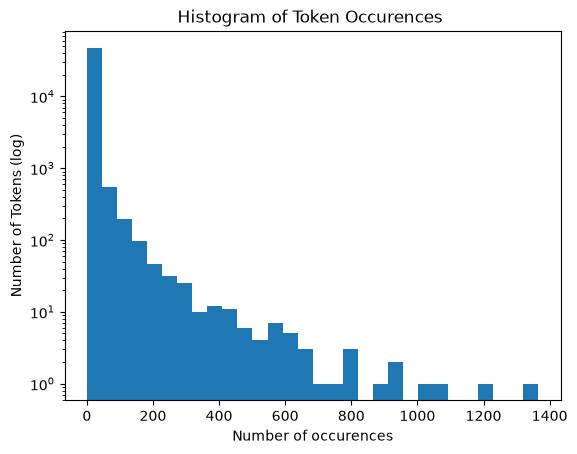

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

token_hist = list(token_count.values()) # Make the counts a list to plot

plt.hist(token_hist, bins=30) # Plot the histogram

plt.title("Histogram of Token Occurences ")
plt.xlabel("Number of occurences")
plt.ylabel("Number of Tokens (log)")
plt.yscale('log') # Transform the long tail
plt.show()

In [41]:
token_count

Counter({'new': 1365,
         'date': 1202,
         'get': 1052,
         'please': 1022,
         'enron': 927,
         'like': 923,
         '2002': 869,
         'would': 806,
         'one': 798,
         'message': 795,
         'call': 740,
         'free': 691,
         'software': 680,
         'dear': 651,
         'know': 644,
         'email': 629,
         'url:': 625,
         'time': 609,
         'start': 604,
         'linguistics': 598,
         'online': 591,
         'need': 587,
         'wrote:': 585,
         'see': 554,
         'conference': 553,
         'language': 550,
         'want': 548,
         'empty': 546,
         'hourahead': 526,
         'list': 523,
         'attached': 515,
         'hello': 501,
         'university': 500,
         '2001': 489,
         'information': 473,
         'vince': 473,
         'may': 461,
         'good': 449,
         'following': 448,
         'hour': 446,
         '2000': 442,
         'business': 442,
         

In [55]:
counts = pd.Series(list(token_count.values())) # make token count a series

print(f"Distinct tokens: {len(counts):,}")
print(f"Number of tokens with 5 or less occurences: {counts.between(1,5).sum():,} ({(counts.between(1,5).sum()/len(counts)):.1%})")


Distinct tokens: 48,691
Number of tokens with 5 or less occurences: 42,450 (87.2%)


The frequency of occurence of different tokens has a very long right tail. The most common words are "new" with 1,365 occurences, "date" with 1,202 occurences, "get" with 1,052 occurences, and "please" with 1,022 occurences. The long right tail means that a few words appear very frequently, but then the frequency of occurence decreases sharply. For example, although the most frequently occuring token is "new" with 1,365 occurences, the 10th most frequently occuring token is 'message' with 795 tokens. There are a lot of tokens that rarely appear, as 87.2% of the tokens have a count of 5 or less. I was also suprised that 'enron' appeared 927 times given that it isn't a common word.

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

In [43]:
df = pd.read_parquet('./data/Phishing_clean.parquet') # Open parquet file
df.head()

,Email Type,new,date,get,please,enron,like,2002,would,one,...,ï¿½ï¿½,safety,yap,ypil,maintain,procedures,tip,elizabeth,leadership,italian
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


**1. Perform an 80/20 train-test split of the data.**

In [44]:
from sklearn.model_selection import train_test_split

print("Rows prior to split:", len(df))

X = df.drop(columns='Email Type') # All columns except email type are feature variables
y = df['Email Type'] # Email type is the outcome variable
X_train, X_test, y_train, y_test = train_test_split(X, y,
    test_size=0.2, random_state=65) # Split data into train and valid sets

print("Rows of training set after split:", len(X_train))


Rows prior to split: 18634
Rows of training set after split: 14907


After performing an 80/20 split, I checked that the length of the training set was what I expected. It was since 80% of 18,634 is about 14,907.

**2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?**

In [45]:
from sklearn.linear_model import LinearRegression

sk_fit = LinearRegression().fit(X_train, y_train) # Fit the linear regression on the training set
print("R-squared on train set:", round(sk_fit.score(X_train, y_train), 4)) # Determine r-squared of training set
print("R-squared on test set:", round(sk_fit.score(X_test, y_test), 4)) # Determine r-squared of test set

R-squared on train set: 0.7678
R-squared on test set: 0.6571


R-squared on the training set is 0.77, while r-squared on the test set is 0.66. 

**3. What words have the largest coefficients in absolute value and most strongly influence predictions?**

In [46]:
features = X.columns
coefficients = abs(pd.Series(sk_fit.coef_, index=features).round(4)) # Determine absolute value of coefficients
coefficients.sort_values(ascending=False) # Sort by largest first

aging                0.9965
helvetica,           0.8922
localized            0.7879
background-image:    0.7801
thermal              0.6710
                      ...  
1994                 0.0000
06,                  0.0000
6th                  0.0000
-0700                0.0000
23,                  0.0000
Length: 2711, dtype: float64

The top 5 tokens that have the largest coefficients in absolute terms and most strongly influence predictions are 'aging', 'helvetica,', 'localized', 'background-image:', and 'thermal'. 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

In [47]:
from sklearn.decomposition import PCA

pca_tokens = PCA(n_components=2).fit(X) # Reduce to 2 components
X_pca = pca_tokens.transform(X)
print("Rows and score columns:", X_pca.shape)
print("Explained variance:", pca_tokens.explained_variance_ratio_.round(3))
print("Combined variance:", np.cumsum(pca_tokens.explained_variance_ratio_).round(3))

Rows and score columns: (18634, 2)
Explained variance: [0.011 0.009]
Combined variance: [0.011 0.02 ]


PC1 explains 1.1% of the variance and PC2 explains 0.9%. Combined these 2 components explain 2% of all data variation.

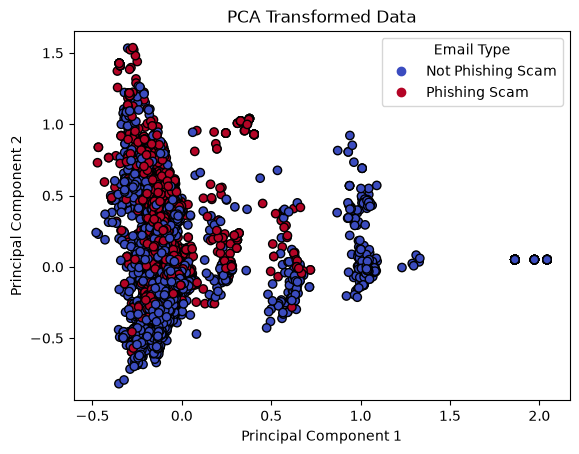

In [48]:
pca_scatterplot = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='coolwarm', edgecolor='k') # Plot first two principle components
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Transformed Data")
plt.legend(handles=pca_scatterplot.legend_elements()[0],labels=["Not Phishing Scam", "Phishing Scam"], title="Email Type") # Create a legend
plt.show()

In general, as PC1 increases, the emails are more likely to not be phishing scam, and as PC2 increases, the email types are generally more likely to be phishing scam. The plot of the first two principal components shows roughly 5 different clusters forming. The three clusters when PC1 is lower than approximately 1 contain both email types (phishing versus non-phishing). When PC1 is around 1 or higher, all the email types are not phishing scam. In the largest cluster that holds most of the emails, when PC1 is mostly negative, the two groups overlap heavily. This means that the two principal components don't separate phishing from non-phishing emails particularly well, although a high PC1 does identify non-phishing emails. This makes sense based on my explained variance calculations above, as these two principal components only capture 2% of the variance of the data. 

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

In [49]:
pca_reg = PCA(n_components=2610).fit(X_train) # Fit PCA on training set
X_train_pca = pca_reg.transform(X_train)
X_test_pca = pca_reg.transform(X_test)

pca_fit = LinearRegression().fit(X_train_pca, y_train) # Fit the linear regression on the training set

print("R-squared on train set:", round(pca_fit.score(X_train_pca, y_train), 4)) # Determine r-squared of training set
print("R-squared on test set:", round(pca_fit.score(X_test_pca, y_test), 4)) # Determine r-squared of test set

print("Combined variance:", np.cumsum(pca_reg.explained_variance_ratio_).round(5)[2609])

R-squared on train set: 0.7669
R-squared on test set: 0.6614
Combined variance: 0.99985


Keeping the first 2,610 principal components of X retains 99.99% of the total variance. With PCA, the r-squared of the training set is 0.7669 and the test set is 0.6614. The linear regression without PCA had a training set r-squared of 0.7678, while r-squared on the test set was 0.6571. Between the two, after PCA the training set r-squared went down slightly while the test set r-squared went up slightly. This means that the model predicts the new test emails only slightly better than without PCA and that the difference between the performance of the training versus test set was smaller. These changes are very small and the models perform almost the same because the vast majority of the variance (99.99%) was retained. Keeping the first 2,610 principal components versus the original 2,711 token features isn't a huge reduction in number of features.

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

When running a high-dimensional regression, PCA allows you to combine features that may contain overlapping information into fewer variables while retaining most of the variation in the data. This dimension reduction is helpful because it can make the model less prone to overfitting, since fewer variables lead to fewer coefficients that can fit noise in the training emails, and faster to fit, since there are fewer coefficients to estimate. Without PCA, you keep all of the original variables, but many of the words columns can overlap, which makes the coefficients harder to estimate. With PCA, the lowest variance components are dropped since the principal components are ordered by how much variance they explain. In this case, keeping 2,610 components retained 99.99% of the variance, and the test r-squared increased slightly (from 0.6571 to 0.6614) while the training r-squared decreased slightly. Due to these changes, the difference between the training and test r-squared decreased from 0.111 to 0.106. This means that dropping the components I did removed a small amount of noise that the original model was overfitting to.

---

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [50]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]